# College golf — data cleaning

This notebook does one job: turn `data/d3_data.csv` into a dataset where **every round is 18 real,
correctly-labelled holes**. It does no analysis. The analysis notebook reads the files written at
the bottom and never has to think about data quality again.

**Unit of cleaning: the round, not the hole.** The raw file has exactly 18 rows for every
player-round, so a round is either trustworthy as a whole or it is not. Dropping individual bad
holes leaves 4-, 9- and 17-hole fragments behind, so a round that fails any check is removed
entirely.

**Scope: everything.** Men and women, tournaments and qualifiers are all cleaned with the same
rules. Scope filters (`team_gender`, `tournament_level`) are an analysis decision and stay in the
analysis notebook.

**Outputs** (written to `data/`):

| file | grain | contents |
|---|---|---|
| `d3_clean_holes.parquet` | one row per hole | only rounds that passed every check; always 18 rows per round |
| `d3_clean_rounds.parquet` | one row per round | round totals for the same rounds |
| `d3_round_audit.parquet` | one row per **raw** round | `status` = `kept` or the reason it was dropped, plus the diagnostics behind the decision |
| `d3_cleaning_summary.csv` | one row per reason | the drop table |

**How the checks are layered**

1. **Structure** — the raw file is what we think it is (18 rows per round, unique keys).
2. **Card checks** — things you can see on a single scorecard: unscored holes, summary rows,
   placeholder cards, impossible scores, half-cards filled in from a total.
3. **Field checks** — things you can only see by comparing a round with everyone else who played
   that course that day: two courses sharing hole numbers, pars that do not match the scores,
   whole events fabricated from round totals.
4. **Duplicate checks** — the same card entered twice.

Each section states the rule, shows the evidence for it in a graph, and ends with a test. A failed
test stops the notebook.

## 0. Configuration

Every threshold used anywhere below is declared here and nowhere else.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- files ----
DATA_DIR    = Path("data")
RAW_PATH    = DATA_DIR / "d3_data.csv"
OUT_HOLES   = DATA_DIR / "d3_clean_holes.parquet"
OUT_ROUNDS  = DATA_DIR / "d3_clean_rounds.parquet"
OUT_AUDIT   = DATA_DIR / "d3_round_audit.parquet"
OUT_SUMMARY = DATA_DIR / "d3_cleaning_summary.csv"
WRITE_CSV   = False        # also write the two clean tables as .csv (large)

# ---- keys ----
ROUND_KEYS = ["tournament_id", "round_number", "player_id"]   # one player's round
FIELD_KEYS = ["tournament_id", "round_number", "layout_id"]   # everyone on the same course that day
N_HOLES    = 18

# ---- card checks ----
VALID_PARS       = (3, 4, 5, 6)
PAR6_MIN_YARDS   = 550     # a par 6 is only believed on a hole at least this long
MAX_OVER_PAR     = 15      # a single hole cannot exceed par + this
FLAT_NINE_LEN    = 9       # a whole nine (holes 1-9 or 10-18) of identical scores ...
FLAT_RUN_ANY_LEN = 12      # ... or a run this long anywhere on the card ...
FLAT_RUN_MIN_OFF = 3       # ... containing this many non-par holes is a total spread across holes

# ---- field checks ----
MIN_FIELD           = 4    # fewer players than this on a course and its pars cannot be verified
PAR_RESPONSE_FLOOR_SHARE = 0.70  # floor = this share of the typical par response for that gender
PAR_RESPONSE_REF_PLAYERS = 20    # "typical" = median over fields with at least this many players
PAR_RESPONSE_Z      = 1.645 # fail only when the 95% upper bound is still below the floor
FABRICATED_MEAN_RUN = 5.0  # field-average longest run of identical scores (normal is about 3)
SALVAGE_SCHOOL_MIN_PLAYERS = 4     # a school needs this many players to be judged on its own
SALVAGE_SCHOOL_MIN_CORR    = 0.55  # school hole-means vs par: right course ~0.8, wrong course ~0
SALVAGE_MIN_KEPT           = 10    # a rescued half-field must still have this many players
SALVAGE_MIN_SEPARATION     = 0.30  # gap required between the lowest kept and highest dropped school

# ---- value repairs (the row is kept, the value is blanked) ----
YARDAGE_BOUNDS = {3: (70, 300), 4: (180, 560), 5: (200, 720), 6: (PAR6_MIN_YARDS, 800)}

# ---- kept but labelled ----
EXTREME_ROUND_MEDIAN_TO_PAR = 5    # is_extreme_round: median hole is +5 or worse (real, but an outlier)

# ---- plotting ----
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": "#52514e", "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110,
})

# ---- tests ----
TESTS = []

def check(name, passed, detail=""):
    "Record a test. A failure stops the notebook."
    passed = bool(passed)
    TESTS.append({"test": name, "passed": passed, "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))
    assert passed, f"TEST FAILED: {name}  {detail}"

pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_colwidth", 46)

## 1. Load and verify the structure

Everything downstream relies on one structural fact: **each player-round is exactly 18 rows, holes
1 to 18**. If that holds, the file can be reshaped into one scorecard per row
(`rounds x 18` matrices of score, par and yardage), which makes every card-level rule a one-line
array operation.

In [2]:
raw = pd.read_csv(RAW_PATH, low_memory=False, dtype={"course_id": "string"})
n_raw_rows = len(raw)

raw = raw.sort_values(ROUND_KEYS[:3] + ["hole_number"], kind="stable").reset_index(drop=True)

check("raw row count is a multiple of 18", n_raw_rows % N_HOLES == 0, f"{n_raw_rows:,} rows")
check("every round is holes 1..18 in order",
      (raw["hole_number"].to_numpy().reshape(-1, N_HOLES) == np.arange(1, N_HOLES + 1)).all())
check("no missing values in key or score columns",
      raw[ROUND_KEYS[:3] + ["hole_number", "par", "score", "to_par", "yardage",
                            "team_gender", "tournament_level", "school_id"]].notna().all().all())
check("to_par == score - par on every row", (raw["score"] - raw["par"] == raw["to_par"]).all())

# one row per round (first of each block of 18) + the scorecard matrices
META = ["tournament_id", "round_number", "player_id", "tournament_name", "tournament_level",
        "tournament_start_date", "tournament_end_date", "round_date", "team_gender",
        "school_id", "school_name", "player_name", "course_id"]
rounds = raw.iloc[::N_HOLES][META].reset_index(drop=True)
S = raw["score"].to_numpy().reshape(-1, N_HOLES)      # scores
P = raw["par"].to_numpy().reshape(-1, N_HOLES)        # pars
Y = raw["yardage"].to_numpy().reshape(-1, N_HOLES)    # yardages
n_raw_rounds = len(rounds)

check("round key (tournament, round, player) is unique", not rounds.duplicated(ROUND_KEYS[:3]).any(),
      f"{n_raw_rounds:,} rounds")
check("one school and one gender per round",
      (raw.groupby(ROUND_KEYS[:3], sort=False)[["school_id", "team_gender"]].nunique() == 1).all().all())
check("no tournament mixes genders",
      (rounds.groupby("tournament_id")["team_gender"].nunique() == 1).all())

rounds["segment"] = rounds["team_gender"] + " " + rounds["tournament_level"].str.title()
print()
print(rounds.groupby(["team_gender", "tournament_level"]).size().rename("raw rounds").to_frame().T.to_string())

[PASS] raw row count is a multiple of 18  (3,034,656 rows)
[PASS] every round is holes 1..18 in order
[PASS] no missing values in key or score columns
[PASS] to_par == score - par on every row
[PASS] round key (tournament, round, player) is unique  (168,592 rounds)
[PASS] one school and one gender per round
[PASS] no tournament mixes genders

team_gender             Men                 Women           
tournament_level QUALIFYING TOURNAMENT QUALIFYING TOURNAMENT
raw rounds             2053     104468        747      61324


## 2. Card checks — what a single scorecard can tell us

| reason | rule | what it is |
|---|---|---|
| `no_card` | all 18 holes are 0 | did not start / no card returned |
| `nine_hole_round` | exactly one nine is scored | a round shortened to 9 holes |
| `incomplete_card` | any other 0 | withdrew mid-round or a hole was never entered |
| `invalid_par` | a par outside 3–6, or a par 6 shorter than 550 yards | a summary row (for example the front-nine total) sitting in a hole slot |
| `placeholder_card` | two or more 1s, or all 18 scores identical | `1 1 1 … 1 <total>` and `5 5 5 … 5` cards |
| `impossible_score` | a hole above par + 15, or a 1 on a par 4 or longer | a total or a typo in a hole slot |

A score of 0 is never a real score, and a real par 6 exists in this data (it is 638 yards and the
field averages 5.9 on it), so par 6 is allowed when the hole is long enough to be one.

In [3]:
unscored   = (S == 0).sum(axis=1)
front_only = (S[:, :9] > 0).all(axis=1) & (S[:, 9:] == 0).all(axis=1)
back_only  = (S[:, :9] == 0).all(axis=1) & (S[:, 9:] > 0).all(axis=1)

par_ok   = np.isin(P, VALID_PARS) & ~((P == 6) & (Y < PAR6_MIN_YARDS))
n_ones   = (S == 1).sum(axis=1)
all_same = (S == S[:, [0]]).all(axis=1)

flag = pd.DataFrame(index=rounds.index)
flag["no_card"]          = unscored == N_HOLES
flag["nine_hole_round"]  = front_only | back_only
flag["incomplete_card"]  = (unscored > 0) & ~flag["no_card"] & ~flag["nine_hole_round"]
flag["invalid_par"]      = ~par_ok.all(axis=1)
flag["placeholder_card"] = (n_ones >= 2) | (all_same & (unscored == 0))
flag["impossible_score"] = ((S > P + MAX_OVER_PAR) | ((S == 1) & (P >= 4))).any(axis=1)

CARD_REASONS = list(flag.columns)
card_ok = ~flag[CARD_REASONS].any(axis=1).to_numpy()
rounds["unscored_holes"] = unscored

print("Rounds failing each card check (a round can fail more than one):")
print(flag[CARD_REASONS].groupby(rounds["segment"]).sum().T.assign(total=flag[CARD_REASONS].sum()).to_string())
print(f"\nRounds with a complete, plausible card: {card_ok.sum():,} of {n_raw_rounds:,}")

def show_cards(idx, title, n=6):
    "Print raw scorecards (scores | pars) for a handful of rounds."
    print(f"\n{title}")
    for i in list(idx)[:n]:
        print(f"  {str(rounds.at[i, 'tournament_name'])[:34]:34s} {str(rounds.at[i, 'player_name'])[:14]:14s} "
              + " ".join(f"{v:>2d}" for v in S[i]) + "  | par " + " ".join(str(v) for v in P[i]))

show_cards(rounds.index[flag["placeholder_card"] & (unscored == 0)], "placeholder_card examples:")
show_cards(rounds.index[flag["invalid_par"] & (unscored == 0)], "invalid_par examples (hole 18 holds the front-nine total):", 3)
show_cards(rounds.index[flag["impossible_score"] & ~flag["placeholder_card"] & ~flag["invalid_par"]],
           "impossible_score examples:", 4)

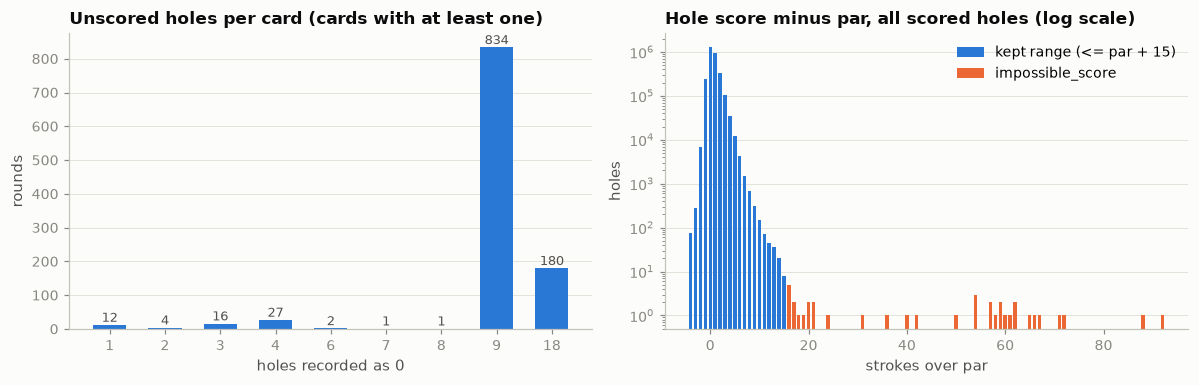

nine-hole rounds: 823 rounds in 39 tournament-rounds; in 35 of those the whole field played nine holes (a shortened round, not withdrawals).
[PASS] card reasons cover every card with an unscored hole
[PASS] every surviving card has 18 scored holes with par 3-6 and score in [1, par+15]


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

# (a) how many holes are unscored on a card
ax = axes[0]
vc = pd.Series(unscored).value_counts().sort_index()
vc = vc[vc.index > 0]
ax.bar(vc.index.astype(str), vc.values, color=BLUE, width=0.6)
for x, v in zip(vc.index.astype(str), vc.values):
    ax.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8.5, color="#52514e")
ax.set_title("Unscored holes per card (cards with at least one)")
ax.set_xlabel("holes recorded as 0"); ax.set_ylabel("rounds"); ax.grid(axis="x", visible=False)

# (b) every hole score relative to par, log scale, with the believable range marked
ax = axes[1]
ok_par = np.isin(P, (3, 4, 5, 6)) & (S > 0)
d = pd.Series((S - P)[ok_par]).value_counts().sort_index()
inside = (d.index <= MAX_OVER_PAR)
ax.bar(d.index[inside], d.values[inside], color=BLUE, width=0.7, label=f"kept range (<= par + {MAX_OVER_PAR})")
ax.bar(d.index[~inside], d.values[~inside], color=ORANGE, width=0.7, label="impossible_score")
ax.set_yscale("log"); ax.set_title("Hole score minus par, all scored holes (log scale)")
ax.set_xlabel("strokes over par"); ax.set_ylabel("holes"); ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

nine = flag["nine_hole_round"].to_numpy()
ev = rounds.assign(nine=nine).groupby(["tournament_id", "round_number"])["nine"].agg(["sum", "size"])
ev = ev[ev["sum"] > 0]
print(f"nine-hole rounds: {nine.sum():,} rounds in {len(ev)} tournament-rounds; "
      f"in {int((ev['sum'] == ev['size']).sum())} of those the whole field played nine holes "
      f"(a shortened round, not withdrawals).")

check("card reasons cover every card with an unscored hole",
      ((unscored > 0) == flag[["no_card", "nine_hole_round", "incomplete_card"]].any(axis=1)).all())
check("every surviving card has 18 scored holes with par 3-6 and score in [1, par+15]",
      ((S[card_ok] >= 1) & (S[card_ok] <= P[card_ok] + MAX_OVER_PAR) & np.isin(P[card_ok], VALID_PARS)).all())

### 2b. Half-cards filled in from a total

Some cards carry real scores on one nine and a nine-hole **total spread evenly** over the other:
`4 4 4 4 4 4 4 4 4 | 4 3 4 3 4 5 2 4 5`. Nothing on such a card is individually impossible, so
the rule looks at the *shape* instead:

> a run of identical consecutive scores **covers a whole nine** (holes 1–9 or 10–18), or is 12 or
> more holes long anywhere on the card, **and** at least 3 holes in the run are not pars.

Nine straight 4s is fine if they are nine pars. Nine straight 4s across par 3s and par 5s means a
bogey on every par 3 and a birdie on every par 5, in a row.

**The evidence is in where the runs start.** A genuine streak can begin on any hole. A spread
total begins on hole 1 or hole 10. The left chart shows exactly that excess, and the test below
it puts a p-value on it. Runs of 9 that start anywhere else are at the level chance predicts, so
they are left alone. The rule will still catch a small number of genuine cards (a real streak that
happens to fill a nine); that is accepted, because the alternative is keeping invented scores.

In [5]:
def longest_identical_run(S, P):
    "Per card: length of the longest run of identical scores, non-par holes inside it, and its first hole."
    n = len(S)
    cur = np.ones(n, dtype=int)
    cur_off = (S[:, 0] != P[:, 0]).astype(int)
    best, best_off, best_end = cur.copy(), cur_off.copy(), np.zeros(n, dtype=int)
    for j in range(1, N_HOLES):
        same = S[:, j] == S[:, j - 1]
        off = (S[:, j] != P[:, j]).astype(int)
        cur = np.where(same, cur + 1, 1)
        cur_off = np.where(same, cur_off + off, off)
        better = cur > best
        best = np.where(better, cur, best)
        best_off = np.where(better, cur_off, best_off)
        best_end = np.where(better, j, best_end)
    return best, best_off, best_end - best + 2

run_len, run_off, run_start = longest_identical_run(S, P)
rounds["longest_run"], rounds["run_offpar_holes"], rounds["run_start_hole"] = run_len, run_off, run_start

run_end = run_start + run_len - 1
covers_nine = (run_len >= FLAT_NINE_LEN) & ((run_start == 1) | (run_end == N_HOLES))
is_flat = (covers_nine | (run_len >= FLAT_RUN_ANY_LEN)) & (run_off >= FLAT_RUN_MIN_OFF)

flag["flat_card"] = card_ok & is_flat
print(f"flat_card: {flag['flat_card'].sum():,} rounds")
show_cards(rounds.index[flag["flat_card"] & (run_len <= 10)], "flat_card examples (one nine flat, the other real):", 6)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

# (a) where do long runs start?  expected: flat.  observed: spikes at 1 and 10.
ax = axes[0]
sel = card_ok & (run_len == 9) & (run_off >= FLAT_RUN_MIN_OFF)
starts = pd.Series(run_start[sel]).value_counts().reindex(range(1, 11), fill_value=0)
colors = [ORANGE if h in (1, 10) else BLUE for h in starts.index]
ax.bar(starts.index, starts.values, color=colors, width=0.6)
from matplotlib.patches import Patch
ax.set_xticks(range(1, 11))
ax.legend(handles=[Patch(color=ORANGE, label="fills a whole nine (flagged)"), Patch(color=BLUE, label="anywhere else (kept)")],
          loc="upper center")
ax.set_title("Where 9-hole runs with 3+ non-par holes start")
ax.set_xlabel("hole the run starts on"); ax.set_ylabel("rounds"); ax.grid(axis="x", visible=False)

# (b) run length: a geometric tail is chance, the lift above it is fabrication
ax = axes[1]
vc = pd.Series(run_len[card_ok]).value_counts().sort_index()
ax.plot(vc.index, vc.values, color=BLUE, lw=2, marker="o", ms=5, label="observed")
fit = vc.loc[5:8]
ratio = (fit.iloc[-1] / fit.iloc[0]) ** (1 / 3)
xs = np.arange(5, 19)
ax.plot(xs, fit.iloc[0] * ratio ** (xs - 5), color=ORANGE, lw=2, ls="--",
        label=f"chance (geometric, x{ratio:.2f} per extra hole)")
ax.set_yscale("log"); ax.set_ylim(0.5, None); ax.set_xticks(range(1, 19, 2))
ax.set_title("Longest run of identical scores per card (log scale)")
ax.set_xlabel("run length (holes)"); ax.set_ylabel("rounds"); ax.legend()
plt.tight_layout(); plt.show()

from scipy.stats import binomtest
n_nine_aligned, n_runs = int(starts[[1, 10]].sum()), int(starts.sum())
bt = binomtest(n_nine_aligned, n_runs, 2 / 10, alternative="greater")
check("9-hole off-par runs fill a whole nine more often than chance (2 of 10 possible start holes)",
      bt.pvalue < 0.001, f"{n_nine_aligned} of {n_runs} = {n_nine_aligned / n_runs:.0%} vs 20% expected, p = {bt.pvalue:.1e}")
elsewhere = starts.drop([1, 10])
check("9-hole runs starting elsewhere show no such excess (flat across start holes)",
      elsewhere.max() < 2 * elsewhere.mean(), f"{elsewhere.min()}-{elsewhere.max()} per start hole")

usable = card_ok & ~flag["flat_card"].to_numpy()     # cards allowed to inform the field checks

## 3. Field checks — what only the rest of the field can tell us

### 3a. Course layouts: who actually played the same holes?

`course_id` cannot be used to define a field. It is missing for hundreds of tournament-rounds, and
in two-course events it is the *same* for both courses. A scorecard's own **18 pars and 18
yardages** identify the course far better, so that signature becomes `layout_id`.

From here on, "the field" is `(tournament_id, round_number, layout_id)`. This is the key the
analysis notebook should use for any field average.

A layout carried by fewer than 4 players inside a larger event is an `orphan_layout`: one or two
cards tagged with a different course than everyone else, which cannot be benchmarked against
anyone. A course with fewer than 4 players in total is `field_too_small` to verify at all.

tournament-rounds with one layout : 4,652
tournament-rounds with two layouts: 20   (3,207 rounds)
orphan_layout  : 5 rounds
field_too_small: 180 rounds


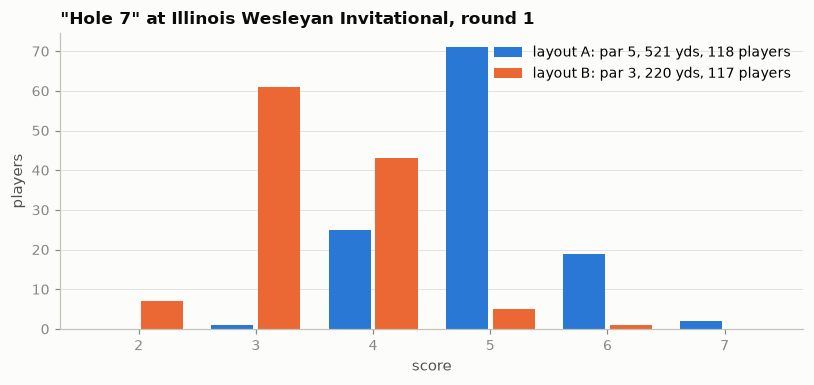

One field average over both groups would benchmark every player against a hole they did not play.
[PASS] every usable round has a layout and a field size


In [6]:
_, layout_id = np.unique(np.concatenate([P, Y], axis=1), axis=0, return_inverse=True)
rounds["layout_id"] = layout_id.astype(np.int64)

u = rounds[usable]
field_n = u.groupby(FIELD_KEYS).size().rename("field_players")
event_n = u.groupby(FIELD_KEYS[:2]).size().rename("event_players")
layouts_in_event = field_n.groupby(level=[0, 1]).size().rename("layouts_in_event")

rounds = rounds.join(field_n, on=FIELD_KEYS).join(event_n, on=FIELD_KEYS[:2]).join(layouts_in_event, on=FIELD_KEYS[:2])
fp = rounds["field_players"].fillna(0)

flag["orphan_layout"]   = usable & (fp < MIN_FIELD) & (rounds["event_players"] - fp >= MIN_FIELD)
flag["field_too_small"] = usable & (fp < MIN_FIELD) & ~flag["orphan_layout"]

multi = layouts_in_event[layouts_in_event > 1]
print(f"tournament-rounds with one layout : {(layouts_in_event == 1).sum():,}")
print(f"tournament-rounds with two layouts: {len(multi):,}   "
      f"({int(u.join(multi.rename('m'), on=FIELD_KEYS[:2])['m'].notna().sum()):,} rounds)")
print(f"orphan_layout  : {flag['orphan_layout'].sum():,} rounds")
print(f"field_too_small: {flag['field_too_small'].sum():,} rounds")

# ---- the picture: one "hole number", two different golf holes ----
big = field_n[field_n >= 20].reset_index()
big = big[big.groupby(FIELD_KEYS[:2])["layout_id"].transform("size") == 2]
best = None
for (t, r), g in big.groupby(FIELD_KEYS[:2]):
    ia, ib = [rounds.index[usable & (rounds["tournament_id"] == t) & (rounds["round_number"] == r)
                           & (rounds["layout_id"] == l)].to_numpy() for l in g["layout_id"]]
    gap = np.abs(P[ia[0]] - P[ib[0]])
    if gap.max() >= 2 and (best is None or len(ia) + len(ib) > best[0]):
        best = (len(ia) + len(ib), t, r, int(gap.argmax()), ia, ib)

_, t, r, h, ia, ib = best
fig, ax = plt.subplots(figsize=(7.5, 3.6))
lo, hi = int(min(S[ia, h].min(), S[ib, h].min())), int(max(S[ia, h].max(), S[ib, h].max()))
xs = np.arange(lo, hi + 1)
for off, idx, col in [(-0.2, ia, BLUE), (0.2, ib, ORANGE)]:
    cnt = pd.Series(S[idx, h]).value_counts().reindex(xs, fill_value=0)
    ax.bar(xs + off, cnt.values, width=0.36, color=col,
           label=f"layout A: par {P[idx[0], h]}, {Y[idx[0], h]} yds, {len(idx)} players" if col == BLUE
           else f"layout B: par {P[idx[0], h]}, {Y[idx[0], h]} yds, {len(idx)} players")
ax.set_xticks(xs); ax.grid(axis="x", visible=False)
ax.set_title(f'"Hole {h + 1}" at {rounds.at[ia[0], "tournament_name"]}, round {r}')
ax.set_xlabel("score"); ax.set_ylabel("players"); ax.legend()
plt.tight_layout(); plt.show()
print("One field average over both groups would benchmark every player against a hole they did not play.")

check("every usable round has a layout and a field size", rounds.loc[usable, "field_players"].notna().all())

### 3b. Do the pars agree with the scores? (par response)

Scores carry their own evidence about par. Regress hole score on hole par across a field:

$$\text{score} = a + b \cdot \text{par}$$

In real golf a hole that is one par longer costs close to one more stroke, so **b is about 0.85
for men and 1.04 for women**. When the pars attached to a field are not the pars of the course
those players were on, the relationship disappears and **b falls to about 0**. If half the field
was on a different course, b lands near 0.4.

Because the typical value differs by gender, the floor is relative: **70% of the median par
response for that gender** (about 0.60 for men and 0.73 for women). A field fails when even the
95% upper confidence bound of `b` is below its floor. Using the bound, not the point estimate, is
what protects small fields from being dropped for noise. Fields that sit just above the floor are
given the benefit of the doubt: an easy set of par 5s and a hard set of par 3s can do that
honestly.

A flagged field is then classified:

* `fabricated_field` — the field's cards are flat (average longest run of identical scores of 5
  or more; normal is about 3). The whole event was entered as round totals spread across holes.
  Dropped. This applies on its own too: a handful of small fields are flat without failing the
  par test.
* **mixed-course field** — some schools track the pars and some do not. See 3c.
* `wrong_pars` — real-looking scores, wrong pars, no school can be rescued. Dropped: the scores
  are fine but `par`, `to_par` and `yardage` describe a different course.

typical par response: {'Men': 0.854, 'Women': 1.037}   floor: {'Men': 0.598, 'Women': 0.726}
fields tested: 4,600   failing the par test: 49  (2,009 rounds)   fabricated: 13 (6 of them small fields that pass the par test)

typical par response in fields of 20+ players:
              count     1%    50%    max
team_gender                             
Men          1715.0  0.576  0.854  1.274
Women        1118.0  0.709  1.037  1.420


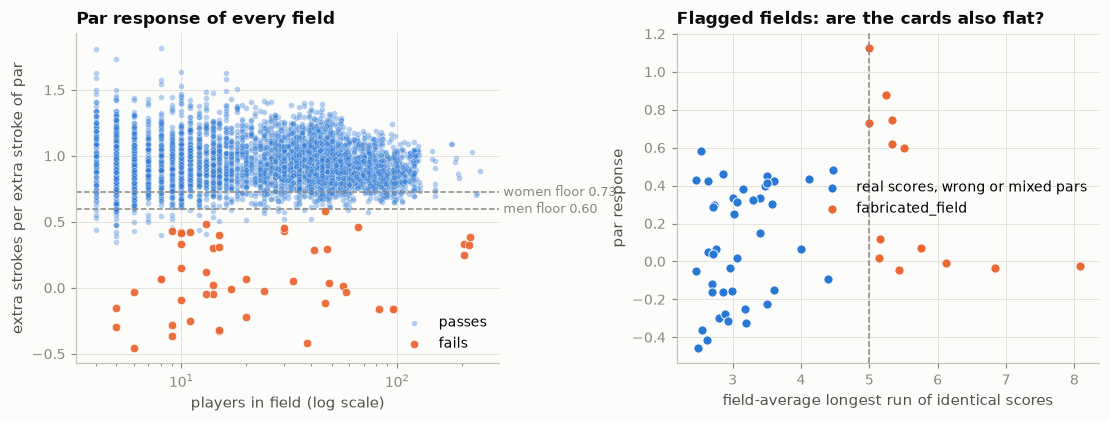


flagged fields:
                               tournament_name  round_number team_gender  players  par_response  upper  mean_longest_run  fabricated
                           Clarke Fall Classic             1         Men        6         -0.46  -0.20              2.50       False
         Westminster Women's Fall Invitational             1       Women       38         -0.41  -0.26              2.63       False
                Final 36 hole Qualifying - UAA             1       Women        9         -0.36  -0.18              2.56       False
                     NCCAA Regional Tournament             1         Men       15         -0.32  -0.16              3.20       False
                     NCCAA Regional Tournament             2         Men       15         -0.32  -0.16              2.93       False
                         ALC Fall Invitational             1         Men        5         -0.30  -0.06              2.80       False
                  FDU-Florham vs. Misericordia      

In [7]:
def par_response(idx_groups):
    "OLS slope of score on par (and its standard error) for each group of round positions."
    out = []
    for key, idx in idx_groups:
        x, y = P[idx].ravel().astype(float), S[idx].ravel().astype(float)
        sxx = ((x - x.mean()) ** 2).sum()
        b = ((x - x.mean()) * (y - y.mean())).sum() / sxx
        resid = y - y.mean() - b * (x - x.mean())
        se = np.sqrt((resid ** 2).sum() / (len(x) - 2) / sxx)
        out.append((key, len(idx), b, se))
    return pd.DataFrame(out, columns=["key", "players", "par_response", "se"])

testable = usable & (fp >= MIN_FIELD).to_numpy()
pos = pd.Series(np.flatnonzero(testable), index=pd.MultiIndex.from_frame(rounds.loc[testable, FIELD_KEYS]))
groups = [(k, v.to_numpy()) for k, v in pos.groupby(level=[0, 1, 2])]

fields = par_response(groups)
fields[FIELD_KEYS] = pd.DataFrame(fields["key"].tolist(), index=fields.index)
fields["upper"] = fields["par_response"] + PAR_RESPONSE_Z * fields["se"]
fields["mean_longest_run"] = [run_len[idx].mean() for _, idx in groups]
first = [idx[0] for _, idx in groups]
fields["tournament_name"] = rounds["tournament_name"].to_numpy()[first]
fields["team_gender"] = rounds["team_gender"].to_numpy()[first]

TYPICAL = fields[fields["players"] >= PAR_RESPONSE_REF_PLAYERS].groupby("team_gender")["par_response"].median()
FLOOR = (TYPICAL * PAR_RESPONSE_FLOOR_SHARE).to_dict()
fields["floor"] = fields["team_gender"].map(FLOOR)
fields["fails"] = fields["upper"] < fields["floor"]
print("typical par response:", {k: round(v, 3) for k, v in TYPICAL.items()},
      "  floor:", {k: round(v, 3) for k, v in FLOOR.items()})
fields["fabricated"] = fields["mean_longest_run"] >= FABRICATED_MEAN_RUN

print(f"fields tested: {len(fields):,}   failing the par test: {fields['fails'].sum()}  "
      f"({fields.loc[fields['fails'], 'players'].sum():,} rounds)   fabricated: {fields['fabricated'].sum()} "
      f"({(fields['fabricated'] & ~fields['fails']).sum()} of them small fields that pass the par test)")
print("\ntypical par response in fields of 20+ players:")
print(fields[fields["players"] >= 20].groupby("team_gender")["par_response"]
      .describe(percentiles=[.01, .5]).round(3)[["count", "1%", "50%", "max"]].to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"wspace": 0.42})
ax = axes[0]
for mask, col, lab in [(~fields["fails"], BLUE, "passes"), (fields["fails"], ORANGE, "fails")]:
    ax.scatter(fields.loc[mask, "players"], fields.loc[mask, "par_response"], s=14 if col == BLUE else 30,
               color=col, alpha=0.35 if col == BLUE else 0.95, edgecolor=SURFACE, linewidth=0.4, label=lab)
for g_, fl in FLOOR.items():
    ax.axhline(fl, color=MUTED, lw=1, ls="--")
    ax.text(1.01, fl, f"{g_.lower()} floor {fl:.2f}", transform=ax.get_yaxis_transform(), va="center", fontsize=8.5, color=MUTED)
ax.set_xscale("log"); ax.set_title("Par response of every field")
ax.set_xlabel("players in field (log scale)"); ax.set_ylabel("extra strokes per extra stroke of par")
ax.legend(loc="lower right")

ax = axes[1]
f = fields[fields["fails"] | fields["fabricated"]]
for mask, col, lab in [(~f["fabricated"], BLUE, "real scores, wrong or mixed pars"), (f["fabricated"], ORANGE, "fabricated_field")]:
    ax.scatter(f.loc[mask, "mean_longest_run"], f.loc[mask, "par_response"], s=36, color=col,
               edgecolor=SURFACE, linewidth=0.6, label=lab)
ax.axvline(FABRICATED_MEAN_RUN, color=MUTED, lw=1, ls="--")
ax.set_title("Flagged fields: are the cards also flat?")
ax.set_xlabel("field-average longest run of identical scores"); ax.set_ylabel("par response")
ax.legend(loc="center right")
plt.show()

print("\nflagged fields:")
print(fields[fields["fails"] | fields["fabricated"]].sort_values("par_response")
      [["tournament_name", "round_number", "team_gender", "players", "par_response", "upper", "mean_longest_run", "fabricated"]]
      .round(2).to_string(index=False))

big = fields[fields["players"] >= 20].copy()
big["rel"] = big["par_response"] / big["team_gender"].map(TYPICAL)
check("passing fields of 20+ players all reach at least half the typical par response",
      (big.loc[~big["fails"], "rel"] > 0.5).all(), f"lowest passing field is at {big.loc[~big['fails'], 'rel'].min():.0%} of typical")
check("failing fields of 20+ players are all well below typical (under 70%)",
      (big.loc[big["fails"], "rel"] < PAR_RESPONSE_FLOOR_SHARE).all(), f"highest failing field is at {big.loc[big['fails'], 'rel'].max():.0%} of typical")
check("failures are rare (under 3% of fields), so the rule is not trimming ordinary golf",
      fields["fails"].mean() < 0.03, f"{fields['fails'].mean():.2%}")

### 3c. Rescuing the half of a mixed-course field that has the right pars

In a few large events two courses were used but **one** par set was attached to everyone. The
field as a whole fails 3b, yet half of it is labelled correctly. Teams play a course together, so
the split is by school.

For each school in a failing (non-fabricated) field: average its players' scores hole by hole and
correlate those 18 hole means with the 18 pars. A school on the labelled course lands around 0.8.
A school on the other course lands around 0.

* schools at or above `0.55` are **kept**,
* everyone else in that field is dropped as `wrong_course_labels` (including individuals and
  schools with fewer than 4 players, who cannot be judged),
* the rescue only stands if the schools form **two clearly separated clusters** (a gap of at least
  0.30 in correlation between the lowest kept and the highest dropped school), the kept group has
  at least 10 players, **and** the kept group passes the par-response test on its own. Otherwise
  the whole field is `wrong_pars`.

fabricated_field   : 128 rounds
wrong_pars         : 1,075 rounds
wrong_course_labels: 414 rounds dropped; 424 rescued in 4 fields


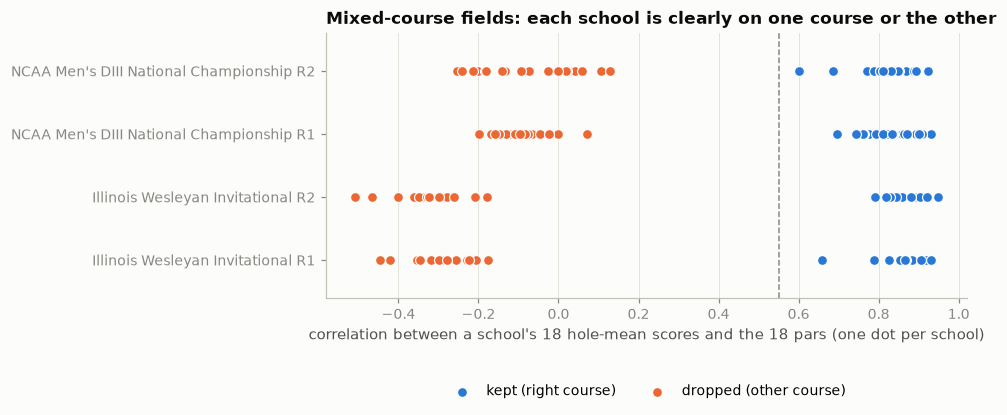

[PASS] in rescued fields no school sits near the cut-off (clean two-cluster split)  (highest dropped 0.13, lowest kept 0.60)
[PASS] every rescued half-field responds to par like a normal field (at least 80% of typical)  (par response 0.79 to 0.89)


In [8]:
school = rounds["school_id"].to_numpy()
flag["fabricated_field"] = False
flag["wrong_pars"] = False
flag["wrong_course_labels"] = False
salvage_rows = []

for (key, idx), (_, f) in zip(groups, fields.iterrows()):
    if f["fabricated"]:
        flag.loc[idx, "fabricated_field"] = True
        continue
    if not f["fails"]:
        continue
    keep = np.zeros(len(idx), dtype=bool)
    for s in np.unique(school[idx]):
        m = school[idx] == s
        corr = np.nan
        if m.sum() >= SALVAGE_SCHOOL_MIN_PLAYERS:
            corr = np.corrcoef(S[idx[m]].mean(axis=0), P[idx[0]])[0, 1]
            keep |= m & (corr >= SALVAGE_SCHOOL_MIN_CORR)
        salvage_rows.append({"key": key, "tournament_name": f["tournament_name"], "round_number": key[1],
                             "school_id": s, "players": int(m.sum()), "school_par_corr": corr})
    corrs = pd.Series([r_["school_par_corr"] for r_ in salvage_rows if r_["key"] == key]).dropna()
    lo_side, hi_side = corrs[corrs < SALVAGE_SCHOOL_MIN_CORR], corrs[corrs >= SALVAGE_SCHOOL_MIN_CORR]
    two_clusters = len(lo_side) > 0 and len(hi_side) > 0 and hi_side.min() - lo_side.max() >= SALVAGE_MIN_SEPARATION
    rescued = False
    if two_clusters and keep.sum() >= SALVAGE_MIN_KEPT:
        re = par_response([(key, idx[keep])]).iloc[0]
        rescued = re["par_response"] >= f["floor"]
    if rescued:
        flag.loc[idx[~keep], "wrong_course_labels"] = True
    else:
        flag.loc[idx, "wrong_pars"] = True
    for row in salvage_rows:
        if row["key"] == key:
            row["field_rescued"] = rescued

sal = pd.DataFrame(salvage_rows)
rescued_keys = sal.loc[sal["field_rescued"], "key"].drop_duplicates().tolist()
print(f"fabricated_field   : {flag['fabricated_field'].sum():,} rounds")
print(f"wrong_pars         : {flag['wrong_pars'].sum():,} rounds")
print(f"wrong_course_labels: {flag['wrong_course_labels'].sum():,} rounds dropped; "
      f"{sum(len(i) for k, i in groups if k in rescued_keys) - flag['wrong_course_labels'].sum():,} rescued "
      f"in {len(rescued_keys)} fields")

# ---- the picture: school correlations are two clean clusters, not a spread ----
fig, ax = plt.subplots(figsize=(9, 0.62 * len(rescued_keys) + 1.6))
labels = []
for row_i, key in enumerate(rescued_keys):
    g = sal[(sal["key"] == key) & sal["school_par_corr"].notna()]
    kept = g["school_par_corr"] >= SALVAGE_SCHOOL_MIN_CORR
    ax.scatter(g.loc[kept, "school_par_corr"], np.full(kept.sum(), row_i), s=42, color=BLUE,
               edgecolor=SURFACE, linewidth=0.8, label="kept (right course)" if row_i == 0 else None)
    ax.scatter(g.loc[~kept, "school_par_corr"], np.full((~kept).sum(), row_i), s=42, color=ORANGE,
               edgecolor=SURFACE, linewidth=0.8, label="dropped (other course)" if row_i == 0 else None)
    labels.append(f"{g['tournament_name'].iloc[0][:44]} R{key[1]}")
ax.axvline(SALVAGE_SCHOOL_MIN_CORR, color=MUTED, lw=1, ls="--")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels); ax.set_ylim(-0.6, len(labels) - 0.4)
ax.set_xlabel("correlation between a school's 18 hole-mean scores and the 18 pars (one dot per school)")
ax.set_title("Mixed-course fields: each school is clearly on one course or the other")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.28)); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

judged = sal[sal["field_rescued"] & sal["school_par_corr"].notna()]
gap_lo = judged.loc[judged["school_par_corr"] < SALVAGE_SCHOOL_MIN_CORR, "school_par_corr"].max()
gap_hi = judged.loc[judged["school_par_corr"] >= SALVAGE_SCHOOL_MIN_CORR, "school_par_corr"].min()
check("in rescued fields no school sits near the cut-off (clean two-cluster split)",
      gap_hi - gap_lo >= SALVAGE_MIN_SEPARATION, f"highest dropped {gap_lo:.2f}, lowest kept {gap_hi:.2f}")
resc = par_response([(k, i[~flag.loc[i, "wrong_course_labels"].to_numpy()]) for k, i in groups if k in rescued_keys])
check("every rescued half-field responds to par like a normal field (at least 80% of typical)",
      (resc["par_response"] > 0.8 * TYPICAL.min()).all(), f"par response {resc['par_response'].min():.2f} to {resc['par_response'].max():.2f}")

## 4. Duplicate checks

Two complete 18-hole cards matching hole for hole is not something that happens by chance. The
cell below estimates how many coincidental matches to expect and compares with what is observed.

| reason | rule | action |
|---|---|---|
| `repeat_of_own_round` | a player's card is identical to one of their earlier rounds in the same tournament | the later round is dropped (the earlier one is kept) |
| `twin_card` | two different players in the same tournament-round have identical cards | both are dropped, because there is no way to tell whose card it is |

In [9]:
card_bytes = pd.Series([row.tobytes() for row in S.astype(np.int16)], index=rounds.index)
c = rounds.loc[card_ok, ["tournament_id", "round_number", "player_id"]].assign(card=card_bytes[card_ok])

c = c.sort_values(["tournament_id", "player_id", "round_number"])
repeat = c.duplicated(["tournament_id", "player_id", "card"], keep="first")
twin = c.duplicated(["tournament_id", "round_number", "card"], keep=False)

flag["repeat_of_own_round"] = False
flag["twin_card"] = False
flag.loc[repeat.index[repeat], "repeat_of_own_round"] = True
flag.loc[twin.index[twin], "twin_card"] = True

# chance of two independent cards matching: product over holes of P(two players score the same)
tp = (S - P)[card_ok]
p_same_hole = (pd.Series(tp.ravel()).value_counts(normalize=True) ** 2).sum()
p_same_card = p_same_hole ** N_HOLES
pairs_within_round = (c.groupby(["tournament_id", "round_number"]).size().pipe(lambda n: n * (n - 1) / 2)).sum()
pairs_own_rounds = (c.groupby(["tournament_id", "player_id"]).size().pipe(lambda n: n * (n - 1) / 2)).sum()

survivors = ~flag.drop(columns=["repeat_of_own_round", "twin_card"]).any(axis=1)
print(f"P(two players match on one hole) = {p_same_hole:.3f}  ->  P(match on all 18) = {p_same_card:.1e}")
print(f"twin cards         : expected by chance {pairs_within_round * p_same_card:.2f} pairs, "
      f"observed {flag['twin_card'].sum():,} rounds ({(flag['twin_card'] & survivors).sum():,} not already dropped)")
print(f"own-round repeats  : expected by chance {pairs_own_rounds * p_same_card:.3f}, "
      f"observed {flag['repeat_of_own_round'].sum():,} rounds ({(flag['repeat_of_own_round'] & survivors).sum():,} not already dropped)")

rep = rounds[flag["repeat_of_own_round"] & survivors].groupby("tournament_name").size().sort_values(ascending=False)
print("\nrepeats cluster inside a few events (a copied round, not a coincidence):")
print(rep.head(6).to_string())
show_cards(rounds.index[flag["twin_card"] & survivors], "twin_card examples (consecutive lines are different players):", 6)

check("identical cards are far more common than chance allows (so they are entry errors)",
      flag["twin_card"].sum() > 20 * max(pairs_within_round * p_same_card, 0.5))

## 5. One status per round

A round can trip several checks. It is given the **first** reason in the order below, which runs
from "nothing was played" to "everything looks fine except it is a copy". A final pass re-checks
field size, because removing rounds can shrink a field below the minimum.

after other drops: 0 more rounds marked fabricated_field, 0 more marked field_too_small

segment              Men Qualifying  Men Tournament  Women Qualifying  Women Tournament     all  pct_of_raw
status                                                                                                     
kept                           1873          102825               638             59976  165312      98.054
no_card                           0              79                 0               101     180       0.107
nine_hole_round                  98             314                75               336     823       0.488
incomplete_card                  14               4                 1                55      74       0.044
invalid_par                       0              15                 0                13      28       0.017
placeholder_card                  3              22                 2                13      40       0.024
impossible_score                  0            

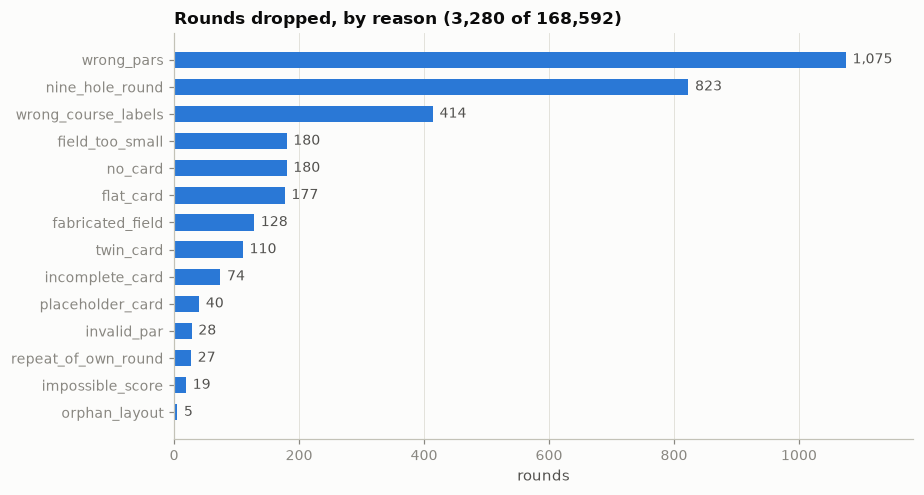

[PASS] every round has exactly one status
[PASS] kept + dropped == raw rounds
[PASS] a kept round trips no check at all


[PASS] the drop reasons are all ones this notebook defines


In [10]:
PRIORITY = ["no_card", "nine_hole_round", "incomplete_card", "invalid_par", "placeholder_card",
            "impossible_score", "flat_card", "orphan_layout", "field_too_small", "fabricated_field",
            "wrong_pars", "wrong_course_labels", "repeat_of_own_round", "twin_card"]
assert set(PRIORITY) == set(flag.columns)

status = np.select([flag[r].to_numpy() for r in PRIORITY], PRIORITY, default="kept")

# removing rounds can leave a field under the minimum -> those rounds can no longer be benchmarked
rounds["status"] = status
k_ = rounds[rounds["status"] == "kept"]
still_flat = k_.groupby(FIELD_KEYS)["longest_run"].transform("mean") >= FABRICATED_MEAN_RUN
rounds.loc[still_flat.index[still_flat], "status"] = "fabricated_field"
left = rounds[rounds["status"] == "kept"].groupby(FIELD_KEYS)["player_id"].transform("size")
shrunk = left.index[left < MIN_FIELD]
rounds.loc[shrunk, "status"] = "field_too_small"
print(f"after other drops: {int(still_flat.sum())} more rounds marked fabricated_field, "
      f"{len(shrunk)} more marked field_too_small")

kept = (rounds["status"] == "kept").to_numpy()
rounds["field_size"] = rounds[kept].groupby(FIELD_KEYS)["player_id"].transform("size")

summary = (rounds.groupby(["status", "segment"]).size().unstack(fill_value=0)
           .reindex(["kept"] + PRIORITY).fillna(0).astype(int))
summary["all"] = summary.sum(axis=1)
summary["pct_of_raw"] = (summary["all"] / n_raw_rounds * 100).round(3)
print()
print(summary.to_string())
print(f"\nkept {kept.sum():,} of {n_raw_rounds:,} rounds ({kept.mean():.2%});  dropped {(~kept).sum():,}")

drops = summary.drop(index="kept")["all"].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh(drops.index, drops.values, color=BLUE, height=0.6)
for y, v in zip(drops.index, drops.values):
    ax.text(v + drops.max() * 0.01, y, f"{v:,}", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, drops.max() * 1.1); ax.grid(axis="y", visible=False)
ax.set_title(f"Rounds dropped, by reason ({(~kept).sum():,} of {n_raw_rounds:,})"); ax.set_xlabel("rounds")
plt.tight_layout(); plt.show()

check("every round has exactly one status", rounds["status"].notna().all() and len(rounds) == n_raw_rounds)
check("kept + dropped == raw rounds", kept.sum() + (~kept).sum() == n_raw_rounds)
check("a kept round trips no check at all", not flag[kept].any(axis=1).any())
check("the drop reasons are all ones this notebook defines", set(rounds["status"]) <= set(PRIORITY) | {"kept"})

## 6. Build the clean tables

Rounds are selected whole, so the hole table is 18 rows per round by construction. Three value-level
repairs are applied to kept rows (the row stays, the untrustworthy value is blanked):

* `yardage` outside a plausible range for its par becomes missing,
* `round_date` outside the tournament's own start and end dates becomes missing (it is also absent
  for about half the file, so prefer `tournament_start_date`),
* `course_name` is dropped (it is empty in every row).

Columns added: `round_id`, `layout_id`, `field_size`, `season_id` / `season_label` (the Aug–May
academic season) and `is_extreme_round`.

`is_extreme_round` marks rounds whose **median** hole is +5 or worse. These are kept on purpose:
the same players post similar scores event after event, so they are real golf by true beginners,
not corrupt data. Whether they belong in a given analysis is an analysis decision, so they are
labelled rather than removed.

In [11]:
keep_rows = np.repeat(kept, N_HOLES)
holes = raw.loc[keep_rows].drop(columns=["course_name"]).reset_index(drop=True)
r_kept = rounds[kept].reset_index(drop=True)

def rep(col):
    return np.repeat(r_kept[col].to_numpy(), N_HOLES)

# ---- added columns ----
holes["round_id"] = np.repeat((r_kept["tournament_id"].astype(str) + "-" + r_kept["round_number"].astype(str)
                               + "-" + r_kept["player_id"].astype(str)).to_numpy(), N_HOLES)
holes["layout_id"]  = rep("layout_id")
holes["field_size"] = rep("field_size").astype(np.int32)
extreme = np.median((S - P)[kept], axis=1) >= EXTREME_ROUND_MEDIAN_TO_PAR
holes["is_extreme_round"] = np.repeat(extreme, N_HOLES)

# ---- dates and season ----
for col in ["tournament_start_date", "tournament_end_date", "round_date"]:
    holes[col] = pd.to_datetime(holes[col], errors="coerce")
bad_date = holes["round_date"].notna() & ~holes["round_date"].between(holes["tournament_start_date"], holes["tournament_end_date"])
holes.loc[bad_date, "round_date"] = pd.NaT
start = holes["tournament_start_date"]
holes["season_id"] = start.dt.year.where(start.dt.month >= 8, start.dt.year - 1).astype(np.int16)
holes["season_label"] = holes["season_id"].astype(str) + "-" + ((holes["season_id"] + 1) % 100).astype(str).str.zfill(2)

# ---- yardage ----
holes["yardage"] = holes["yardage"].astype("float64")
bad_yards = pd.Series(False, index=holes.index)
for par, (lo, hi) in YARDAGE_BOUNDS.items():
    bad_yards |= (holes["par"] == par) & ~holes["yardage"].between(lo, hi)
holes.loc[bad_yards, "yardage"] = np.nan

# ---- types and order ----
for col in ["hole_number", "par", "score", "to_par", "round_number"]:
    holes[col] = holes[col].astype(np.int16)
for col in ["tournament_level", "team_gender", "season_label"]:
    holes[col] = holes[col].astype("category")
holes = holes[["round_id", "tournament_id", "tournament_name", "tournament_level", "tournament_start_date",
               "tournament_end_date", "round_date", "season_id", "season_label", "round_number", "team_gender",
               "school_id", "school_name", "player_id", "player_name", "course_id", "layout_id", "field_size",
               "hole_number", "par", "yardage", "score", "to_par", "is_extreme_round"]]

# ---- one row per round ----
ROUND_META = ["round_id", "tournament_id", "tournament_name", "tournament_level", "tournament_start_date",
              "tournament_end_date", "round_date", "season_id", "season_label", "round_number", "team_gender",
              "school_id", "school_name", "player_id", "player_name", "course_id", "layout_id", "field_size",
              "is_extreme_round"]
clean_rounds = holes.iloc[::N_HOLES][ROUND_META].reset_index(drop=True)
Sk, Pk = S[kept], P[kept]
clean_rounds["round_score"]  = Sk.sum(axis=1)
clean_rounds["round_par"]    = Pk.sum(axis=1)
clean_rounds["round_to_par"] = clean_rounds["round_score"] - clean_rounds["round_par"]
clean_rounds["front_nine"]   = Sk[:, :9].sum(axis=1)
clean_rounds["back_nine"]    = Sk[:, 9:].sum(axis=1)
clean_rounds["birdies_or_better"] = (Sk < Pk).sum(axis=1)
clean_rounds["pars"]              = (Sk == Pk).sum(axis=1)
clean_rounds["bogeys"]            = (Sk == Pk + 1).sum(axis=1)
clean_rounds["doubles_or_worse"]  = (Sk >= Pk + 2).sum(axis=1)

print(f"clean holes : {len(holes):,} rows x {holes.shape[1]} columns")
print(f"clean rounds: {len(clean_rounds):,} rows x {clean_rounds.shape[1]} columns")
print(f"yardage blanked: {int(bad_yards.sum()):,} holes    round_date blanked: {int(bad_date.sum()):,} holes")
print(f"is_extreme_round: {int(extreme.sum())} rounds kept and labelled")
holes.head(3)

## 7. Final test suite on the clean tables

These tests run against the finished tables, independently of how they were built. They are the
contract the analysis notebook can rely on.

In [12]:
print("--- shape and keys ---")
per_round = holes.groupby("round_id", sort=False)["hole_number"]
check("every round has exactly 18 rows", (per_round.size() == N_HOLES).all(), f"{holes['round_id'].nunique():,} rounds")
check("every round is holes 1..18, each once", (per_round.nunique() == N_HOLES).all()
      and holes["hole_number"].between(1, N_HOLES).all())
check("(round_id, hole_number) is unique", not holes.duplicated(["round_id", "hole_number"]).any())
check("round_id matches (tournament_id, round_number, player_id) one to one",
      clean_rounds["round_id"].is_unique and not clean_rounds.duplicated(ROUND_KEYS[:3]).any())
check("rounds table and holes table describe the same rounds",
      len(clean_rounds) * N_HOLES == len(holes) and set(clean_rounds["round_id"]) == set(holes["round_id"]))

print("\n--- values ---")
check("no missing score, par, to_par or key", holes[["score", "par", "to_par", "tournament_id", "player_id",
      "school_id", "layout_id", "team_gender", "tournament_level", "season_id"]].notna().all().all())
check("par is 3, 4, 5 or 6", holes["par"].isin(VALID_PARS).all())
check("par 6 only on holes of 550+ yards", (holes.loc[holes["par"] == 6, "yardage"] >= PAR6_MIN_YARDS).all(),
      f"{(holes['par'] == 6).sum()} par-6 holes")
check("1 <= score <= par + 15 on every hole", (holes["score"].between(1, holes["par"] + MAX_OVER_PAR)).all(),
      f"max over par {int(holes['to_par'].max())}")
check("to_par == score - par", (holes["score"] - holes["par"] == holes["to_par"]).all())
check("no hole-in-one on a par 4 or longer", not ((holes["score"] == 1) & (holes["par"] >= 4)).any())
check("no round has two holes-in-one", (holes["score"] == 1).groupby(holes["round_id"], sort=False).sum().max() <= 1)
check("round par is a real course par (64 to 76)", clean_rounds["round_par"].between(64, 76).all(),
      f"range {clean_rounds['round_par'].min()}-{clean_rounds['round_par'].max()}")
check("every remaining yardage is plausible for its par",
      all(holes.loc[(holes["par"] == p) & holes["yardage"].notna(), "yardage"].between(lo, hi).all()
          for p, (lo, hi) in YARDAGE_BOUNDS.items()))
check("every remaining round_date is inside its tournament",
      holes.loc[holes["round_date"].notna()].eval("tournament_start_date <= round_date <= tournament_end_date").all())
check("no tournament starts in June or July (season split is unambiguous)",
      not holes["tournament_start_date"].dt.month.isin([6, 7]).any())

print("\n--- fields ---")
hole_field = holes.groupby(FIELD_KEYS + ["hole_number"], sort=False)
check("one par per hole within a field (no two courses under one hole number)", (hole_field["par"].nunique() == 1).all())
check("one yardage per hole within a field", (hole_field["yardage"].nunique(dropna=False) == 1).all())
check(f"every field has at least {MIN_FIELD} players and field_size is correct",
      (clean_rounds["field_size"] >= MIN_FIELD).all()
      and (clean_rounds.groupby(FIELD_KEYS)["round_id"].transform("size") == clean_rounds["field_size"]).all())
check("no tournament mixes genders", (clean_rounds.groupby("tournament_id")["team_gender"].nunique() == 1).all())

kpos = np.flatnonzero(kept)
gpos = pd.Series(kpos, index=pd.MultiIndex.from_frame(rounds.loc[kept, FIELD_KEYS]))
final_groups = [(k, v.to_numpy()) for k, v in gpos.groupby(level=[0, 1, 2])]
final_fields = par_response(final_groups)
final_fields["upper"] = final_fields["par_response"] + PAR_RESPONSE_Z * final_fields["se"]
final_fields["team_gender"] = [rounds.at[i[0], "team_gender"] for _, i in final_groups]
final_fields["floor"] = final_fields["team_gender"].map(FLOOR)
check("every field passes the par-response test", (final_fields["upper"] >= final_fields["floor"]).all(),
      f"{len(final_fields):,} fields")
ff20 = final_fields[final_fields["players"] >= 20]
check("no field of 20+ players is under half the typical par response",
      (ff20["par_response"] / ff20["team_gender"].map(TYPICAL) > 0.5).all())
check("no fabricated field remains (field-average longest run under 5)",
      max(run_len[i].mean() for _, i in final_groups) < FABRICATED_MEAN_RUN)

print("\n--- cards ---")
check("no flat card remains", not is_flat[kept].any())
kc = rounds.loc[kept, ["tournament_id", "round_number", "player_id"]].assign(card=card_bytes[kept])
check("no two players in a tournament-round share a card", not kc.duplicated(["tournament_id", "round_number", "card"], keep=False).any())
check("no player repeats a card within a tournament", not kc.duplicated(["tournament_id", "player_id", "card"], keep=False).any())

print("\n--- plausibility ---")
for g, grp in holes[holes["par"] == 3].groupby("team_gender", observed=True):
    one_in = len(grp) / max((grp["score"] == 1).sum(), 1)
    check(f"hole-in-one rate on par 3s is believable ({g})", 1500 <= one_in <= 30000, f"1 in {one_in:,.0f}")
pr = final_fields[final_fields["players"] >= 20].groupby("team_gender")["par_response"].median()
check("median par response is near 1 stroke per stroke of par", pr.between(0.75, 1.15).all(),
      ", ".join(f"{k} {v:.2f}" for k, v in pr.items()))

--- shape and keys ---
[PASS] every round has exactly 18 rows  (165,312 rounds)
[PASS] every round is holes 1..18, each once
[PASS] (round_id, hole_number) is unique
[PASS] round_id matches (tournament_id, round_number, player_id) one to one


[PASS] rounds table and holes table describe the same rounds

--- values ---
[PASS] no missing score, par, to_par or key
[PASS] par is 3, 4, 5 or 6
[PASS] par 6 only on holes of 550+ yards  (61 par-6 holes)
[PASS] 1 <= score <= par + 15 on every hole  (max over par 15)
[PASS] to_par == score - par
[PASS] no hole-in-one on a par 4 or longer
[PASS] no round has two holes-in-one
[PASS] round par is a real course par (64 to 76)  (range 65-74)
[PASS] every remaining yardage is plausible for its par
[PASS] every remaining round_date is inside its tournament
[PASS] no tournament starts in June or July (season split is unambiguous)

--- fields ---


[PASS] one par per hole within a field (no two courses under one hole number)
[PASS] one yardage per hole within a field
[PASS] every field has at least 4 players and field_size is correct
[PASS] no tournament mixes genders
[PASS] every field passes the par-response test  (4,549 fields)
[PASS] no field of 20+ players is under half the typical par response
[PASS] no fabricated field remains (field-average longest run under 5)

--- cards ---
[PASS] no flat card remains
[PASS] no two players in a tournament-round share a card


[PASS] no player repeats a card within a tournament

--- plausibility ---
[PASS] hole-in-one rate on par 3s is believable (Men)  (1 in 4,569)
[PASS] hole-in-one rate on par 3s is believable (Women)  (1 in 5,723)
[PASS] median par response is near 1 stroke per stroke of par  (Men 0.85, Women 1.04)


## 8. Did cleaning remove bad data without moving the real signal?

Most of the complete cards that were dropped hold **real scores with the wrong labels** (wrong
pars, wrong course), so their round totals should look like ordinary golf, and removing them
should not move the scoring distribution. Three things should therefore be true:

* the round-score distribution of the dropped complete cards overlaps the kept one, apart from a
  tail of placeholder totals,
* the headline numbers of the kept data barely differ from the raw complete cards, and
* the numbers that **do** move are the ones bad labels inflate: eagles (a 3 on a hole wrongly
  labelled par 5) and holes-in-one (placeholder 1s).

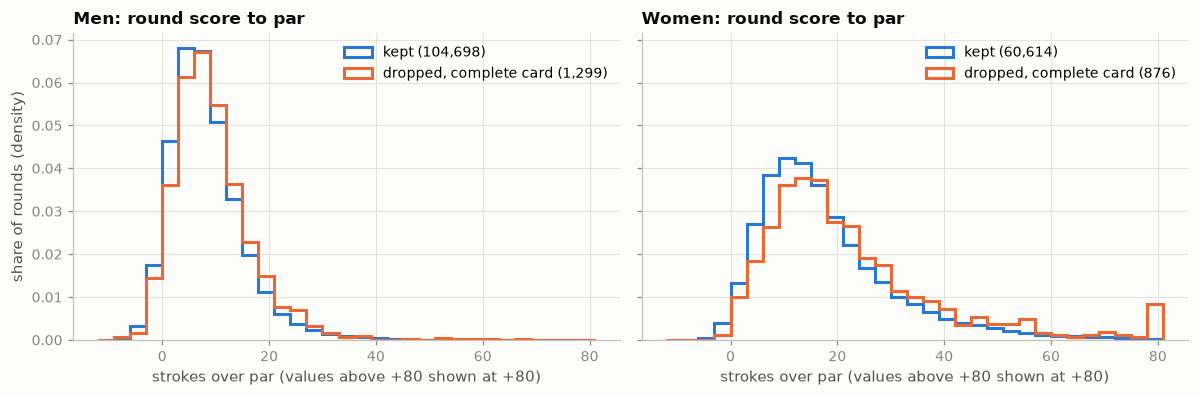

                    Men Tournament             Women Tournament           
                      raw complete       clean     raw complete      clean
rounds                  104056.000  102825.000        60819.000  59976.000
mean round to par            7.950       7.934           17.685     17.608
median round to par          7.000       7.000           15.000     15.000
worst round to par         160.000     160.000          174.000    173.000
eagle or better %            0.311       0.264            0.106      0.075
birdie %                     9.995       9.941            4.725      4.671
par %                       49.149      49.326           34.191     34.352
bogey %                     29.889      29.896           35.007     35.103
double or worse %           10.656      10.573           25.972     25.800
par-3 holes per ace       2858.033    4488.316         3509.875   5933.286
[PASS] mean round score moved by less than 0.15 strokes (Men Tournament)  (0.016)
[PASS] mean round 

In [13]:
seg_order = ["Men Tournament", "Women Tournament", "Men Qualifying", "Women Qualifying"]
complete = (unscored == 0) & par_ok.all(axis=1)          # raw cards with 18 scored holes and real pars
rtp = (S - P).sum(axis=1)

# ---- (a) round to-par: kept vs dropped-but-complete ----
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
bins = np.arange(-12, 82, 3)
for ax, g in zip(axes, ["Men", "Women"]):
    is_g = (rounds["team_gender"] == g).to_numpy()
    k, d = rtp[kept & is_g], np.clip(rtp[complete & ~kept & is_g], None, 80)
    ax.hist(k, bins=bins, density=True, histtype="step", lw=2, color=BLUE, label=f"kept ({len(k):,})")
    ax.hist(d, bins=bins, density=True, histtype="step", lw=2, color=ORANGE, label=f"dropped, complete card ({len(d):,})")
    ax.set_title(f"{g}: round score to par"); ax.set_xlabel("strokes over par (values above +80 shown at +80)")
    ax.legend(loc="upper right")
axes[0].set_ylabel("share of rounds (density)")
plt.tight_layout(); plt.show()

# ---- (b) headline numbers, raw complete cards vs clean ----
def headline(mask):
    tp = (S - P)[mask]
    out = {"rounds": int(mask.sum()), "mean round to par": rtp[mask].mean(), "median round to par": np.median(rtp[mask]),
           "worst round to par": rtp[mask].max(),
           "eagle or better %": (tp <= -2).mean() * 100, "birdie %": (tp == -1).mean() * 100,
           "par %": (tp == 0).mean() * 100, "bogey %": (tp == 1).mean() * 100, "double or worse %": (tp >= 2).mean() * 100}
    par3 = P[mask] == 3
    out["par-3 holes per ace"] = par3.sum() / max(((S[mask] == 1) & par3).sum(), 1)
    return pd.Series(out)

rows = {}
for seg in seg_order[:2]:
    is_s = (rounds["segment"] == seg).to_numpy()
    rows[(seg, "raw complete")] = headline(complete & is_s)
    rows[(seg, "clean")] = headline(kept & is_s)
comp = pd.DataFrame(rows)
print(comp.round(3).to_string())

for seg in seg_order[:2]:
    shift = abs(comp[(seg, "clean")]["mean round to par"] - comp[(seg, "raw complete")]["mean round to par"])
    check(f"mean round score moved by less than 0.15 strokes ({seg})", shift < 0.15, f"{shift:.3f}")
    for k in ["birdie %", "par %", "bogey %", "double or worse %"]:
        dpp = abs(comp[(seg, "clean")][k] - comp[(seg, "raw complete")][k])
        assert dpp < 0.5, (seg, k, dpp)
check("birdie, par, bogey and double rates each moved by less than 0.5 percentage points", True)
for seg in seg_order[:2]:
    b, a = comp[(seg, "raw complete")], comp[(seg, "clean")]
    check(f"the artifacts shrink: fewer eagles and fewer holes-in-one after cleaning ({seg})",
          a["eagle or better %"] < b["eagle or better %"] and a["par-3 holes per ace"] > b["par-3 holes per ace"],
          f"eagles {b['eagle or better %']:.3f}% -> {a['eagle or better %']:.3f}%, one ace per {b['par-3 holes per ace']:,.0f} -> {a['par-3 holes per ace']:,.0f} par 3s")

Hole-level filtering alone would leave these partial rounds in the data:
holes surviving  4   5    9   10  11  12  14  15  16   17
rounds           14   7  834   1   1   2  27  16   6  119
-> 1,027 fragments.  This notebook leaves 0.


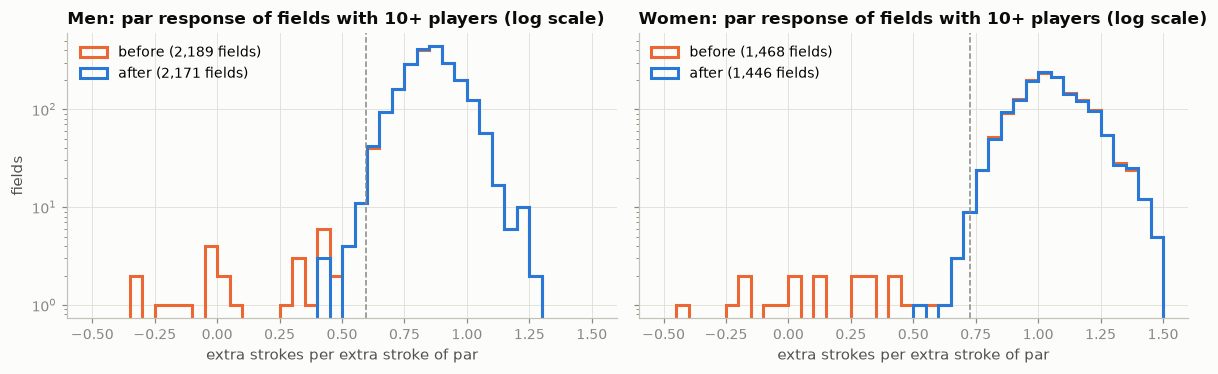


Clean data coverage (tournaments / players / rounds):
                 tournaments                                     players                                      rounds                                 
team_gender              Men      Women        Men      Women        Men      Women        Men      Women        Men      Women        Men      Women
tournament_level  TOURNAMENT TOURNAMENT QUALIFYING QUALIFYING TOURNAMENT TOURNAMENT QUALIFYING QUALIFYING TOURNAMENT TOURNAMENT QUALIFYING QUALIFYING
season_label                                                                                                                                         
2023-24                  411        307          0          0       3013       1748          0          0      29327      17397          0          0
2024-25                  495        385         26          8       3254       1838        179         43      35265      20534        480        131
2025-26                  525        409      

In [14]:
# ---- (c) what "drop bad holes" would have left behind vs "drop bad rounds" ----
hole_valid = (S > 0) & np.isin(P, (3, 4, 5)) & (S <= P + MAX_OVER_PAR) & ~((S == 1) & (P > 3))
left_behind = pd.Series(hole_valid.sum(axis=1)).value_counts().sort_index()
partial = left_behind[(left_behind.index > 0) & (left_behind.index < N_HOLES)]
print("Hole-level filtering alone would leave these partial rounds in the data:")
print(partial.rename("rounds").rename_axis("holes surviving").to_frame().T.to_string())
print(f"-> {int(partial.sum()):,} fragments.  This notebook leaves {int((holes.groupby('round_id', sort=False).size() != N_HOLES).sum())}.")

# ---- (d) par response before and after ----
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
bins = np.arange(-0.5, 1.55, 0.05)
for ax, g in zip(axes, ["Men", "Women"]):
    before = fields[(fields["team_gender"] == g) & (fields["players"] >= 10)]["par_response"]
    after = final_fields[(final_fields["team_gender"] == g) & (final_fields["players"] >= 10)]["par_response"]
    ax.hist(before.clip(-0.5, 1.5), bins=bins, histtype="step", lw=2, color=ORANGE, label=f"before ({len(before):,} fields)")
    ax.hist(after.clip(-0.5, 1.5), bins=bins, histtype="step", lw=2, color=BLUE, label=f"after ({len(after):,} fields)")
    ax.axvline(FLOOR[g], color=MUTED, lw=1, ls="--")
    ax.set_yscale("log"); ax.set_title(f"{g}: par response of fields with 10+ players (log scale)")
    ax.set_xlabel("extra strokes per extra stroke of par"); ax.legend(loc="upper left")
axes[0].set_ylabel("fields")
plt.tight_layout(); plt.show()

# ---- (e) what is in the clean file ----
cov = clean_rounds.groupby(["season_label", "team_gender", "tournament_level"], observed=True).agg(
    tournaments=("tournament_id", "nunique"), players=("player_id", "nunique"), rounds=("round_id", "size")).unstack([1, 2])
print("\nClean data coverage (tournaments / players / rounds):")
print(cov.fillna(0).astype(int).to_string())

## 9. Write the cleaned files

In [15]:
audit = rounds.drop(columns=["segment"]).copy()
audit = audit.join(fields.set_index(FIELD_KEYS)[["par_response", "upper", "mean_longest_run"]]
                   .rename(columns={"par_response": "field_par_response", "upper": "field_par_response_upper",
                                    "mean_longest_run": "field_mean_longest_run"}), on=FIELD_KEYS)
audit["round_score"] = np.where(unscored == 0, S.sum(axis=1), np.nan)
audit["round_to_par"] = np.where(complete, rtp, np.nan)
audit["card"] = [" ".join(map(str, row)) for row in S]
for col in ["field_players", "event_players", "layouts_in_event", "field_size"]:
    audit[col] = audit[col].astype("Int32")

summary_out = summary.reset_index().rename(columns={"index": "status"})

holes.to_parquet(OUT_HOLES, index=False)
clean_rounds.to_parquet(OUT_ROUNDS, index=False)
audit.to_parquet(OUT_AUDIT, index=False)
summary_out.to_csv(OUT_SUMMARY, index=False)
if WRITE_CSV:
    holes.to_csv(OUT_HOLES.with_suffix(".csv"), index=False)
    clean_rounds.to_csv(OUT_ROUNDS.with_suffix(".csv"), index=False)

for path in [OUT_HOLES, OUT_ROUNDS, OUT_AUDIT, OUT_SUMMARY]:
    print(f"wrote {str(path):36s} {path.stat().st_size / 1e6:8.2f} MB")

# read back and confirm the files on disk are the tables that were tested
back = pd.read_parquet(OUT_HOLES)
check("holes file reads back identical", len(back) == len(holes) and list(back.columns) == list(holes.columns)
      and (back["score"].to_numpy() == holes["score"].to_numpy()).all()
      and (back["round_id"].to_numpy() == holes["round_id"].to_numpy()).all())
check("rounds file reads back identical", pd.read_parquet(OUT_ROUNDS)["round_score"].sum() == clean_rounds["round_score"].sum())
check("audit file has one row per raw round", len(pd.read_parquet(OUT_AUDIT, columns=["status"])) == n_raw_rounds)

tests = pd.DataFrame(TESTS)
print(f"\n{int(tests['passed'].sum())} of {len(tests)} tests passed.")

wrote data/d3_clean_holes.parquet              7.11 MB
wrote data/d3_clean_rounds.parquet             3.30 MB
wrote data/d3_round_audit.parquet              4.80 MB
wrote data/d3_cleaning_summary.csv             0.00 MB


[PASS] holes file reads back identical
[PASS] rounds file reads back identical
[PASS] audit file has one row per raw round

59 of 59 tests passed.


## 10. Using the cleaned data

```python
import pandas as pd

holes  = pd.read_parquet("data/d3_clean_holes.parquet")    # one row per hole, 18 per round
rounds = pd.read_parquet("data/d3_clean_rounds.parquet")   # one row per round

# scope is an analysis choice
men = holes[(holes["team_gender"] == "Men") & (holes["tournament_level"] == "TOURNAMENT")]
```

Things the analysis notebook should know:

* **The field is `(tournament_id, round_number, layout_id)`**, not `(tournament_id, round_number)`.
  Add `hole_number` for a hole-level field average. `field_size` is the number of clean rounds in
  that field, so a minimum-field filter is `field_size >= 10`.
* **`round_id`** identifies one player's round and replaces the three-column round key.
* **`is_extreme_round`** rounds are real but very high-scoring. Decide per analysis whether to
  include them.
* **`player_id` is not stable across seasons** for about two dozen players, who were issued a new
  id in 2025-26. Within a season it is safe. `player_name` is an initial plus surname and is not
  unique, so never join on it.
* **`hole_number` is the hole on the card, not the order of play.** Shotgun starts are common in
  college golf, so hole 1 is not necessarily a player's first hole of the day.
* **`yardage` and `round_date` have blanks** where the raw value was not believable.
* To see why any round is missing, look it up in `d3_round_audit.parquet`: `status` gives the
  reason and `card` shows the raw scores.